# How to download a dataset from Pangea



## Problem

I would like to download the drift trajectory for the MOSAiC Central Observatory 1 from the Pangea site.

## Solution

MOSAiC drift trajectories can be found at [https://doi.pangaea.de/10.1594/PANGAEA.937184](https://doi.pangaea.de/10.1594/PANGAEA.937184).  Rather than downloading the data and storing t locally, we can access the data and load it directly into memory using the `pandas` package.

We need to define the URL for the datafile.  This can be found from the _Download Data_ section of the page and right clicking on the download data link.  In this case the data are a tab-delimited file.

The url for the data is the URL for the data page followed by `?format=textfile`.

`https://doi.pangaea.de/10.1594/PANGAEA.937184?format=textfile`

### Import required packages and assign url

In [1]:
import pandas as pd

url = "https://doi.pangaea.de/10.1594/PANGAEA.937184?format=textfile"

### Load data into a `pandas.DataFrame`

We'll use `pandas.read_csv` to load the data.  This file has metadata stored in the file along with data.  So we have to tell `pandas.read_csv` to ignore the rows that contain the data.  This might require you to look at the file.  Here we know there are 23 rows containing metadata, so we set `skiprows=23`.  

We also want to convert the `Date/Time` values to `datetime` objects so we can use the time series functionality of `pandas` and use this column as the _index_ of the DataFrame.  We do this by setting `parse_dates=True` and `index_col=0`

The file is TAB delimited rather than the comma-delimited, so we need to set `delimeter="\t"`, where `\t` is the ASCII code for a TAB. 

In [2]:
df = pd.read_csv(url, delimiter="\t", parse_dates=True, skiprows=23, index_col=0)
df

,Latitude,Longitude
Date/Time,,
2019-10-04 12:00:00,85.1178,134.8906
2019-10-04 13:00:00,85.0798,134.5539
2019-10-04 14:00:00,85.0765,134.3713
2019-10-04 15:00:00,85.0769,134.3179
2019-10-04 16:00:00,85.0771,134.2697
...,...,...
2020-11-11 10:00:00,60.8356,-39.8254
2020-11-11 11:00:00,60.8272,-39.8240
2020-11-11 12:00:00,60.8206,-39.8224


### Plot the data

We'll use `matplotlib` and `cartopy` to plot the data.  We also use the data to create a `geopandas.GeoDataFrame`.  This allows us to use `geopandas` functions to transform the coordinates from latitude and longitude to a Polar Projection for visualising the drift track.  

In [3]:
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

import geopandas as gpd

A `geopandas.GeoDataFrame` is an extension of a `pandas.DataFrame` so that it includes a geometry column.  We use `geopandas.points_from_xy` to create the Point geometry.  We also set the _coordinate reference system_ (CRS) to WGS84, which is done by passing the EPSG code, `EPSG:4326`.  See [Projections and Grids]().

For plotting we don't need the Latitude and Longitude columns any more so we drop these.

In [4]:
gdf = gpd.GeoDataFrame(df, geometry=gpd.points_from_xy(df.Longitude, df.Latitude), crs="EPSG:4326").drop(["Latitude", "Longitude"], axis=1)
gdf

,geometry
Date/Time,
2019-10-04 12:00:00,POINT (134.8906 85.1178)
2019-10-04 13:00:00,POINT (134.5539 85.0798)
2019-10-04 14:00:00,POINT (134.3713 85.0765)
2019-10-04 15:00:00,POINT (134.3179 85.0769)
2019-10-04 16:00:00,POINT (134.2697 85.0771)
...,...
2020-11-11 10:00:00,POINT (-39.8254 60.8356)
2020-11-11 11:00:00,POINT (-39.824 60.8272)
2020-11-11 12:00:00,POINT (-39.8224 60.8206)


We'll plot the drift track on the standard North Polar Stereographic projection.  The default extent of this projection is the whole globe, so we set the extent to north of 60 N.  We also add land and ocean features from the `cartopy.feature` module.

The drift track data is in WGS84, so we use the `to_crs` method to convert latitude and longitude to projected coordinates.  To define the target CRS, we convert the `cartopy` `projection` object to a Well Known Text (WKT) representation. 

To limit the number of points plotted, we select only the 12:00 observations.

<GeoAxes: >

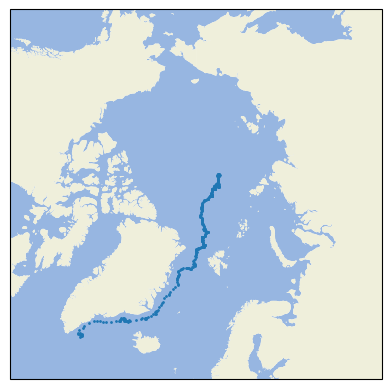

In [5]:
projection = ccrs.NorthPolarStereo()

fig, ax = plt.subplots(subplot_kw={"projection": projection})
ax.set_extent([-180.,180.,60.,90.], ccrs.PlateCarree())
    
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.LAND)

gdf[gdf.index.hour == 12].to_crs(projection.to_wkt()).plot(ax=ax, markersize=1)  # Plot 1200 h

## Discussion

In the example, we treat locations on the drift track as points.  This preserves the timestamp of the drift track.

We could treat the drift track as line-segments with a time range for each segment.

In [6]:
for i, (idx, row) in enumerate(df.iterrows()):
    print(idx, row.Longitude, row.Latitude)
    if i > 5:
        break

2019-10-04 12:00:00 134.8906 85.1178
2019-10-04 13:00:00 134.5539 85.0798
2019-10-04 14:00:00 134.3713 85.0765
2019-10-04 15:00:00 134.3179 85.0769
2019-10-04 16:00:00 134.2697 85.0771
2019-10-04 17:00:00 134.2243 85.0772
2019-10-04 18:00:00 134.1798 85.0772


In [7]:
from shapely.geometry import LineString

sub_df = df[df.index.hour == 12]

geometry = []
attributes = []
index = []
for i in range(1, len(sub_df)):
    seg_beg = sub_df.iloc[i-1]
    seg_end = sub_df.iloc[i]
    geometry.append(
        LineString(
            [
                [seg_beg.Longitude, seg_beg.Latitude],
                [seg_end.Longitude, seg_end.Latitude]
            ]
        )
    )
    attributes.append(
        {
            'start': seg_beg.name,
            'end': seg_end.name
        }
    )
    index.append(seg_beg.name)

gdf_segments = gpd.GeoDataFrame(data=attributes, index=index, geometry=geometry, crs="EPSG:4326")

In [8]:
gdf_segments

,start,end,geometry
2019-10-04 12:00:00,2019-10-04 12:00:00,2019-10-05 12:00:00,"LINESTRING (134.8906 85.1178, 133.7326 85.1003)"
2019-10-05 12:00:00,2019-10-05 12:00:00,2019-10-06 12:00:00,"LINESTRING (133.7326 85.1003, 133.8625 85.1024)"
2019-10-06 12:00:00,2019-10-06 12:00:00,2019-10-07 12:00:00,"LINESTRING (133.8625 85.1024, 134.6276 85.0677)"
2019-10-07 12:00:00,2019-10-07 12:00:00,2019-10-08 12:00:00,"LINESTRING (134.6276 85.0677, 136.2234 84.9562)"
2019-10-08 12:00:00,2019-10-08 12:00:00,2019-10-09 12:00:00,"LINESTRING (136.2234 84.9562, 135.9029 84.9028)"
...,...,...,...
2020-11-06 12:00:00,2020-11-06 12:00:00,2020-11-07 12:00:00,"LINESTRING (-39.7566 61.0392, -39.3834 61.1532)"
2020-11-07 12:00:00,2020-11-07 12:00:00,2020-11-08 12:00:00,"LINESTRING (-39.3834 61.1532, -39.5054 61.2708)"
2020-11-08 12:00:00,2020-11-08 12:00:00,2020-11-09 12:00:00,"LINESTRING (-39.5054 61.2708, -39.8372 61.3556)"
2020-11-09 12:00:00,2020-11-09 12:00:00,2020-11-10 12:00:00,"LINESTRING (-39.8372 61.3556, -39.983 61.1232)"


Calculate velocity

In [10]:
def speed(x):
    dx = x.geometry.length
    dt = (x.end - x.start).total_seconds()
    if dt == 0:
        return 0.0
    else:
        return dx / dt
    
gdf_segments["speed"] = gdf_segments.to_crs("EPSG:6931").apply(speed, axis=1)
gdf_segments.head()

,start,end,geometry,speed
2019-10-04 12:00:00,2019-10-04 12:00:00,2019-10-05 12:00:00,"LINESTRING (134.8906 85.1178, 133.7326 85.1003)",0.129729
2019-10-05 12:00:00,2019-10-05 12:00:00,2019-10-06 12:00:00,"LINESTRING (133.7326 85.1003, 133.8625 85.1024)",0.014607
2019-10-06 12:00:00,2019-10-06 12:00:00,2019-10-07 12:00:00,"LINESTRING (133.8625 85.1024, 134.6276 85.0677)",0.095928
2019-10-07 12:00:00,2019-10-07 12:00:00,2019-10-08 12:00:00,"LINESTRING (134.6276 85.0677, 136.2234 84.9562)",0.230135
2019-10-08 12:00:00,2019-10-08 12:00:00,2019-10-09 12:00:00,"LINESTRING (136.2234 84.9562, 135.9029 84.9028)",0.078096


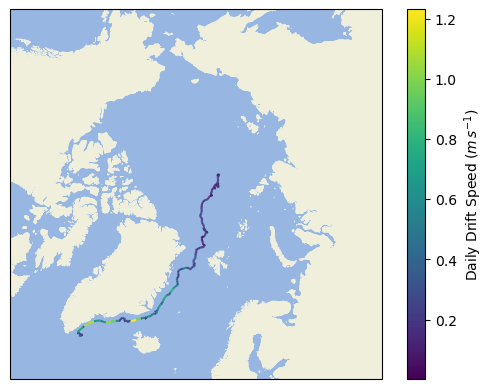

In [11]:
projection = ccrs.NorthPolarStereo()

fig, ax = plt.subplots(subplot_kw={"projection": projection})
ax.set_extent([-180.,180.,60.,90.], ccrs.PlateCarree())
    
ax.add_feature(cfeature.OCEAN)
ax.add_feature(cfeature.LAND)

gdf_segments.to_crs(projection.to_wkt()).plot(
    ax=ax, 
    column="speed", 
    legend=True, 
    legend_kwds={"label": r"Daily Drift Speed ($m\,s^{-1}$)"});